In [1]:
#julia -t 4

using Plots
using Random, Statistics, Distributions
using SparseArrays
using LinearAlgebra
using DifferentialEquations
using StatsPlots 

using Statistics 
using Distributions, Random, Plots, StatsBase  
using Base.Threads



include("../GPs.jl")


log_marginal_extended_exact (generic function with 1 method)

In [43]:


# -------------------------
# Training Data
# -------------------------


X_train = collect(range(-4, 4, length=20))

y_train = sin.(X_train) .+
          0.2 .* randn(length(X_train)) 

σf = 1.0
σn = 0.2

println(y_train.size)

 
#

(20,)


In [9]:
#ℓ = best_ℓ
ℓ = 1.0
σf = 1.0
σn = 0.2

# -------------------------
# Test Points
# -------------------------
X_test = collect(range(-5, 5, length=300))

# -------------------------
# Covariance Matrices
# -------------------------
K =
    kernel_matrix(X_train, X_train;
                  ℓ=ℓ, σf=σf) +
    σn^2 * I

Ks =
    kernel_matrix(X_train, X_test;
                  ℓ=ℓ, σf=σf)

Kss =
    kernel_matrix(X_test, X_test;
                  ℓ=ℓ, σf=σf)

# -------------------------
# Posterior Mean
# -------------------------
μ =
    transpose(Ks) *
    (K \ y_train)

# -------------------------
# Posterior Covariance
# -------------------------
Σ =
    Kss -
    transpose(Ks) *
    (K \ Ks)

std =
    sqrt.(diag(Σ))

#

300-element Vector{Float64}:
 0.7123282646655369
 0.6948141564338861
 0.6768074941505932
 0.6583390588377155
 0.6394430721894447
 0.6201571400179535
 0.6005221748404339
 0.5805822988411453
 0.5603847288336887
 0.539979645243343
 ⋮
 0.5603847288336885
 0.580582298841145
 0.6005221748404337
 0.6201571400179534
 0.6394430721894446
 0.6583390588377153
 0.6768074941505933
 0.6948141564338861
 0.7123282646655369

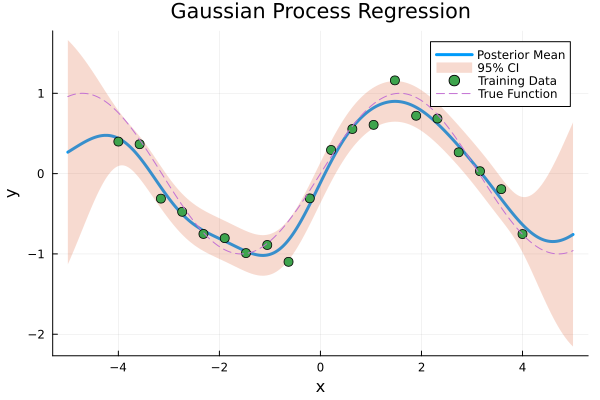

In [10]:
#-------------------------
# Visualization
# -------------------------
plot(
    X_test,
    μ,
    label="Posterior Mean",
    lw=3
)

plot!(
    X_test,
    μ .+ 1.96 .* std,
    fillrange=μ .- 1.96 .* std,
    fillalpha=0.25,
    linealpha=0,
    label="95% CI"
)

scatter!(
    X_train,
    y_train,
    label="Training Data",
    ms=5
)

plot!(
    X_test,
    sin.(X_test),
    ls=:dash,
    label="True Function"
)

xlabel!("x")
ylabel!("y")
title!("Gaussian Process Regression")

In [5]:
#ℓ = best_ℓ
ℓ = 1.0
σf = 1.0
σn = 0.2

# -------------------------
# Test Points
# -------------------------
X_test = collect(range(-5, 5, length=300))

# -------------------------
# Covariance Matrices
# -------------------------
K =
    kernel_matrix(X_train, X_train;
                  ℓ=ℓ, σf=σf) +
    σn^2 * I

Ks =
    kernel_matrix(X_train, X_test;
                  ℓ=ℓ, σf=σf)

Kss =
    kernel_matrix(X_test, X_test;
                  ℓ=ℓ, σf=σf)

# -------------------------
# Posterior Mean
# -------------------------
μ =
    transpose(Ks) *
    (K \ y_train)

# -------------------------
# Posterior Covariance
# -------------------------
Σ =
    Kss -
    transpose(Ks) *
    (K \ Ks)

std =
    sqrt.(diag(Σ))

#

300-element Vector{Float64}:
 0.9999999999643899
 0.9999999999505836
 0.9999999999315816
 0.9999999999054898
 0.9999999998697472
 0.9999999998208987
 0.9999999997542957
 0.9999999996636981
 0.9999999995407517
 0.9999999993742983
 ⋮
 0.9999982418007626
 0.9999986203162111
 0.9999989198600305
 0.999999156335006
 0.9999993425691968
 0.9999994888826788
 0.9999996035556988
 0.9999996932141798
 0.9999997631461789

In [2]:


# -------------------------
# Training Data
# -------------------------
dt = 0.2

X_train = collect(0:dt:1)
y_train = -sin.(2π .* X_train)



println("X_train:", X_train)
println("y_train:", y_train)

println(y_train.size)

 
#

X_train:[0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
y_train:[-0.0, -0.9510565162951535, -0.5877852522924732, 0.587785252292473, 0.9510565162951536, 2.4492935982947064e-16]
(6,)


In [30]:
#ℓ = best_ℓ
ℓ = 2.0
σf = 10.0
σn = 0.2

# -------------------------
# Test Points
# -------------------------
#X_test = collect(range(-5, 5, length=300))

X_test = collect(range(0, 1, length=300))
# -------------------------
# Covariance Matrices
# -------------------------


function laplacian_matrix(n, dt)

    # n = number of grid points (including boundary)
    D = zeros(n-2, n)

    for i in 1:n-2
        D[i,i]   = 1
        D[i,i+1] = -2
        D[i,i+2] = 1
    end

    return D ./ dt^2
end

function laplacian_matrix(n, dt)

    # n = number of grid points (including boundary)
    D = zeros(n-2, n)

    #for i in 1:n-2
    #    D[i,i+1] = 1
    #end

    for i in 1:n-2
        D[i,i]   = 1
        D[i,i+1] = -2
        D[i,i+2] = 1
    end

    return D ./ dt^2
end




function observation_matrix(n, dt)

    D = laplacian_matrix(n, dt)

    H = zeros(n, n)

    # u(0)
    H[1,1] = 1.0

    # Lu (internal)
    H[2:n-1, :] .= D

    # u(1)
    H[end,end] = 1.0

    return H
end

H = observation_matrix(length(X_train), dt)

println("H:", H)
println("H.size:", H.size)



#K =
#    kernel_matrix(X_train, X_train;
#                  ℓ=ℓ, σf=σf) +
#    σn^2 * I

K =
    H * kernel_matrix(X_train, X_train;
                  ℓ=ℓ, σf=σf) * H' +
#    σn^2 * I
     (0.0001) * I

#K =
#    kernel_matrix(X_train, X_train;
#                  ℓ=ℓ, σf=σf)  +
#    σn^2 * I

println("K.size:", K.size)

Ks =
    kernel_matrix(X_train, X_test;
                  ℓ=ℓ, σf=σf)

println("Ks.size:", Ks.size)

Ks = H * Ks

Kss =
    kernel_matrix(X_test, X_test;
                  ℓ=ℓ, σf=σf)

println("Kss.size:", Kss.size)

# -------------------------
# Posterior Mean
# -------------------------
μ =
    transpose(Ks) *
    (K \ y_train)

# -------------------------
# Posterior Covariance
# -------------------------
Σ =
    Kss -
    transpose(Ks) *
    (K \ Ks)

std =
    sqrt.(diag(Σ))

#

H:[1.0 0.0 0.0 0.0 0.0 0.0; 24.999999999999996 -49.99999999999999 24.999999999999996 0.0 0.0 0.0; 0.0 24.999999999999996 -49.99999999999999 24.999999999999996 0.0 0.0; 0.0 0.0 24.999999999999996 -49.99999999999999 24.999999999999996 0.0; 0.0 0.0 0.0 24.999999999999996 -49.99999999999999 24.999999999999996; 0.0 0.0 0.0 0.0 0.0 1.0]
H.size:(6, 6)
K.size:(6, 6)
Ks.size:(6, 300)
Kss.size:(300, 300)


300-element Vector{Float64}:
 0.009999936209567333
 0.009966571678193722
 0.009933335538993431
 0.009900227755141404
 0.009867248380081952
 0.009834397560486274
 0.009801675521853364
 0.009769082575624402
 0.009736619111098714
 0.009704285584974236
 ⋮
 0.00973661911036895
 0.009769082575624402
 0.009801675521128443
 0.00983439755831875
 0.00986724837936185
 0.009900227753705996
 0.009933335538993431
 0.009966571679619575
 0.009999936209567333

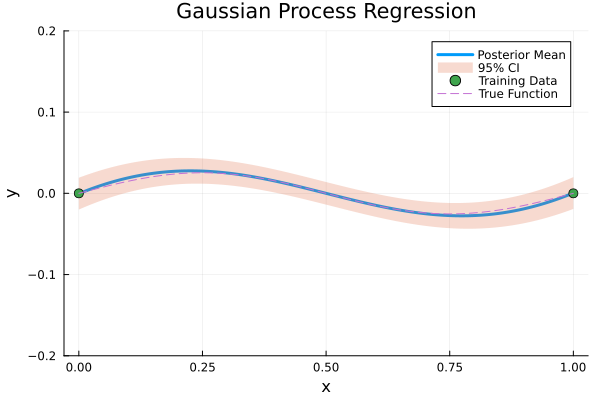

In [33]:
#-------------------------
# Visualization
# -------------------------
plot(
    X_test,
    μ,
    label="Posterior Mean",
    lw=3
)

plot!(
    X_test,
    μ .+ 1.96 .* std,
    fillrange=μ .- 1.96 .* std,
    fillalpha=0.25,
    linealpha=0,
    label="95% CI"
)

scatter!(
    X_train,
    y_train,
    label="Training Data",
    ms=5
)

plot!(
    X_test,
    #sin.(X_test),
    (1/(2π)^2) * sin.(2π .* X_test),
    ylims = (-0.2, 0.2),
    ls=:dash,
    label="True Function"
)

xlabel!("x")
ylabel!("y")
title!("Gaussian Process Regression")